<a href="https://colab.research.google.com/github/pendulumswings/pendulumswings.github.io/blob/main/scripts/chapter5/mathieu_tongues.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

STRUTT DIAGRAM (Parametric Resonance Tongues for Mathieu's Equation)

<>:78: SyntaxWarning: invalid escape sequence '\m'
<>:79: SyntaxWarning: invalid escape sequence '\m'
<>:78: SyntaxWarning: invalid escape sequence '\m'
<>:79: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_1305/3573836837.py:78: SyntaxWarning: invalid escape sequence '\m'
  Patch(facecolor='red', alpha=0.3, label='Red Tongues: UNSTABLE ($\mu = i\omega_b/2$)'),
/tmp/ipykernel_1305/3573836837.py:79: SyntaxWarning: invalid escape sequence '\m'
  Patch(facecolor='blue', alpha=0.15, label='Blue Tongues: UNSTABLE ($\mu = 0$)'),


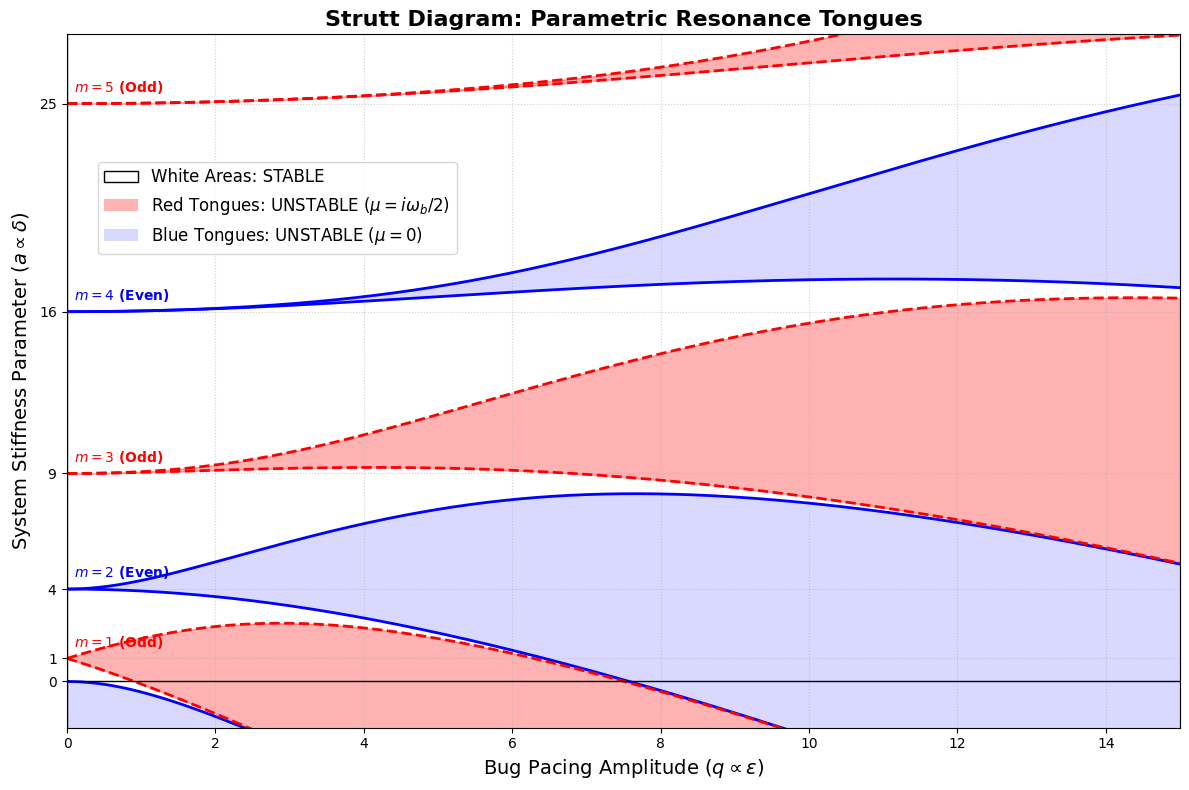

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import mathieu_a, mathieu_b

# ==============================================================================
# STRUTT DIAGRAM (Parametric Resonance Tongues for Mathieu's Equation)
#
# Standard Mathieu Equation: y'' + [a - 2q*cos(2t)]*y = 0
#
# Mapping from our Pendulum:
# a is proportional to the unperturbed pendulum stiffness (delta)
# q is proportional to the bug's pacing amplitude (epsilon)
# ==============================================================================

# Range of the pacing amplitude (q)
q_vals = np.linspace(0, 15, 600)

plt.figure(figsize=(12, 8))
plt.title("Strutt Diagram: Parametric Resonance Tongues", fontsize=16, fontweight='bold')

# ------------------------------------------------------------------------------
# 1. The EVEN Tongues (Period = T) -> Floquet condition: mu = 0
# Plotted in BLUE. These are defined by characteristic values a_even and b_even.
# ------------------------------------------------------------------------------
for m in [0, 2, 4]:
    a_boundary = mathieu_a(m, q_vals)
    plt.plot(q_vals, a_boundary, color='blue', linewidth=2,
             label=r'$\mu = 0$ (Even, T-periodic)' if m == 0 else "")

    if m > 0:
        b_boundary = mathieu_b(m, q_vals)
        plt.plot(q_vals, b_boundary, color='blue', linewidth=2)
        # Fill the unstable resonance tongue
        plt.fill_between(q_vals, b_boundary, a_boundary, color='blue', alpha=0.15)
    else:
        # The lowest boundary (a_0) forms an unstable region dropping to -infinity
        plt.fill_between(q_vals, -10, a_boundary, color='blue', alpha=0.15)

    # Annotate the origin of the tongue
    if m > 0:
        plt.text(0.1, m**2 + 0.5, f'$m={m}$ (Even)', color='blue', fontsize=10, fontweight='bold')

# ------------------------------------------------------------------------------
# 2. The ODD Tongues (Period = 2T) -> Floquet condition: mu = i*omega_b/2
# Plotted in RED. These are defined by characteristic values a_odd and b_odd.
# ------------------------------------------------------------------------------
for m in [1, 3, 5]:
    a_boundary = mathieu_a(m, q_vals)
    b_boundary = mathieu_b(m, q_vals)

    plt.plot(q_vals, a_boundary, color='red', linewidth=2, linestyle='--',
             label=r'$\mu = i\omega_b/2$ (Odd, 2T-periodic)' if m == 1 else "")
    plt.plot(q_vals, b_boundary, color='red', linewidth=2, linestyle='--')

    # Fill the unstable resonance tongue
    plt.fill_between(q_vals, b_boundary, a_boundary, color='red', alpha=0.3)

    # Annotate the origin of the tongue
    plt.text(0.1, m**2 + 0.5, f'$m={m}$ (Odd)', color='red', fontsize=10, fontweight='bold')

# ------------------------------------------------------------------------------
# Formatting and Labels
# ------------------------------------------------------------------------------
plt.axhline(0, color='black', linewidth=1)
plt.axvline(0, color='black', linewidth=1)

# The origins of the tongues at q=0 exactly match our derived delta = (m^2 * w_b^2) / 4
plt.yticks([0, 1, 4, 9, 16, 25], ['0', '$1$', '$4$', '$9$', '$16$', '$25$'])
plt.ylabel(r"System Stiffness Parameter ($a \propto \delta$)", fontsize=14)
plt.xlabel(r"Bug Pacing Amplitude ($q \propto \epsilon$)", fontsize=14)

# Create custom legend entries to describe stability
from matplotlib.patches import Patch
import matplotlib.lines as mlines

legend_elements = [
    Patch(facecolor='white', edgecolor='black', alpha=1.0, label='White Areas: STABLE'),
    Patch(facecolor='red', alpha=0.3, label='Red Tongues: UNSTABLE ($\mu = i\omega_b/2$)'),
    Patch(facecolor='blue', alpha=0.15, label='Blue Tongues: UNSTABLE ($\mu = 0$)'),
]

# Position the legend between the y=16 and y=25 tongues (approx 0.75 in axes fraction)
plt.legend(handles=legend_elements, loc='center left', bbox_to_anchor=(0.02, 0.75), fontsize=12)

plt.xlim(0, 15)
plt.ylim(-2, 28)
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()

# Save or show the plot
plt.savefig('mathieu_tongues.png', dpi=300)
plt.show()